# Lab 4 Homework solutions

## 1. Dane

In [1]:
from itertools import batched
from pathlib import Path

import pandas as pd

DATA = Path("data/images")
metadata = pd.read_csv(DATA / "metadata/images.csv.gz")
metadata = metadata[(metadata["width"] >= 1000) & (metadata["height"] >= 1000)]
image_paths = [DATA / "small" / path for path in metadata["path"]]
image_paths = [path for path in image_paths if path.is_file()]
print("Liczba obrazów:", len(image_paths))

Liczba obrazów: 342878


## 2. Model

CLIP to model multimodalny, który koduje tekst i obrazy we wspólnej przestrzeni wektorowej. Wektor ma **512** elementów. `ViT` oznacza Vision Transformer, `B` — wariant Base, a `32` — fragmenty obrazu o rozmiarze 32 × 32 px.

In [2]:
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer("sentence-transformers/clip-ViT-B-32", device=device)

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

... (2 outputs left out)

0_CLIPModel/pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

0_CLIPModel/model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/604 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


## 3. Baza danych

In [3]:
from pgvector.sqlalchemy import Vector
from sqlalchemy import create_engine, delete, select, text
from sqlalchemy.engine import URL
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column

url = URL.create(
    "postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)
engine = create_engine(url)

with engine.begin() as connection:
    connection.execute(text("CREATE EXTENSION IF NOT EXISTS vectorscale CASCADE"))


class Base(DeclarativeBase):
    pass


class Img(Base):
    __tablename__ = "images"
    __table_args__ = {"extend_existing": True}

    VECTOR_LENGTH = 512

    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column()
    embedding: Mapped[list[float]] = mapped_column(Vector(VECTOR_LENGTH))


Base.metadata.create_all(engine)

## 4. Wektoryzacja

In [4]:
import joblib
from PIL import Image
from tqdm.notebook import tqdm

MAX_IMAGES = 100
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)


def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()


def vectorize_images(engine, model, image_paths):
    paths = image_paths[:MAX_IMAGES]
    with tqdm(total=len(paths)) as pbar:
        for paths_batch in batched(paths, BATCH_SIZE):
            images = []
            for path in paths_batch:
                with Image.open(path) as image:
                    images.append(image.convert("RGB"))
            embeddings = model.encode(images, batch_size=BATCH_SIZE, show_progress_bar=False)
            imgs = [
                Img(image_path=str(path), embedding=embedding.tolist())
                for path, embedding in zip(paths_batch, embeddings)
            ]
            insert_images(engine, imgs)
            for image in images:
                image.close()
            pbar.update(len(imgs))

## 5. Wyszukiwanie

In [5]:
import matplotlib.pyplot as plt


class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int):
        images = self.find_similar_images(image_description, k)
        self.display_images(images)

    def find_similar_images(self, image_description: str, k: int):
        embedding = self.model.encode(image_description).tolist()
        query = (
            select(Img.image_path)
            .order_by(Img.embedding.cosine_distance(embedding))
            .limit(k)
        )
        with Session(self.engine) as session:
            return session.scalars(query).all()

    def display_images(self, images):
        if not images:
            return
        fig, axes = plt.subplots(1, len(images), figsize=(15, 5), squeeze=False)
        for i, path in enumerate(images):
            with Image.open(path) as image:
                axes[0, i].imshow(image)
            axes[0, i].axis("off")
            axes[0, i].set_title(f"Image {i + 1}")
        plt.tight_layout()
        plt.show()

## 6. Porównanie

  0%|          | 0/100 [00:00<?, ?it/s]

Liczba obrazów: 100
a red chair


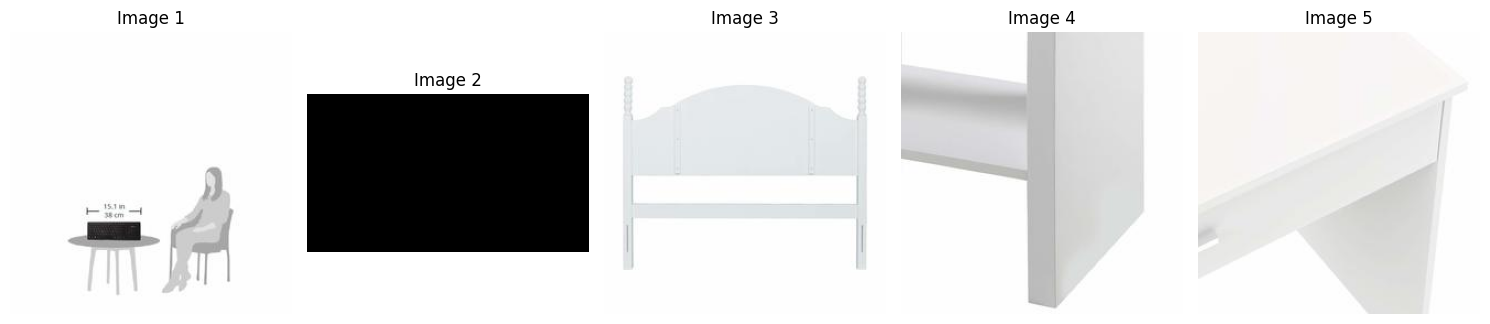

a wooden table


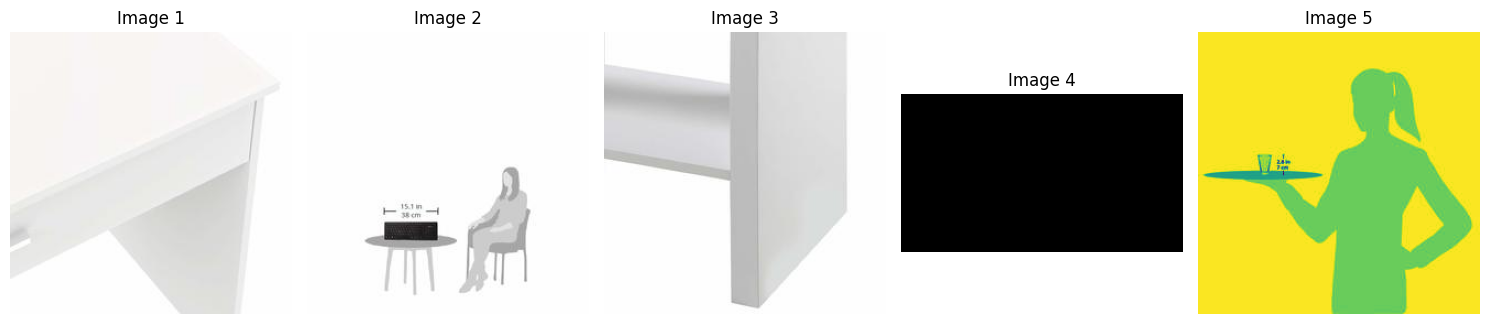

a blue backpack


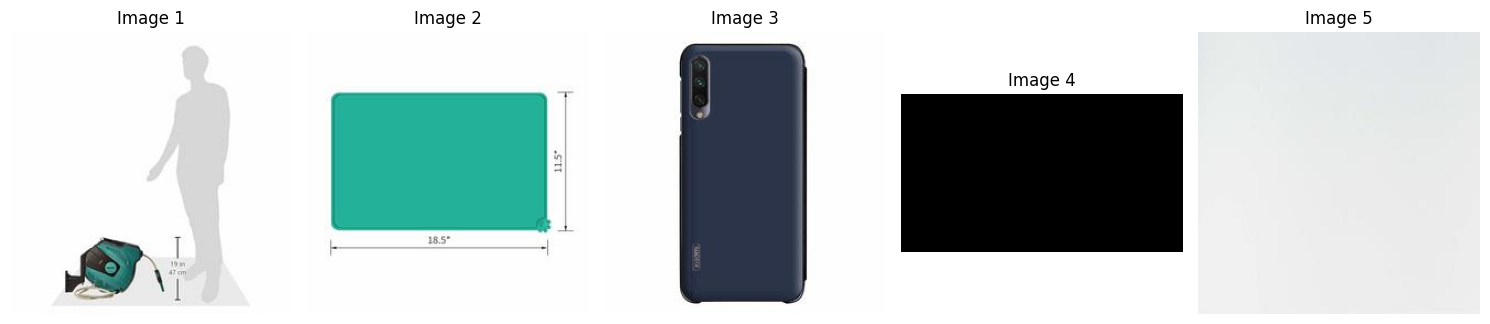

  0%|          | 0/500 [00:00<?, ?it/s]

Liczba obrazów: 500
a red chair


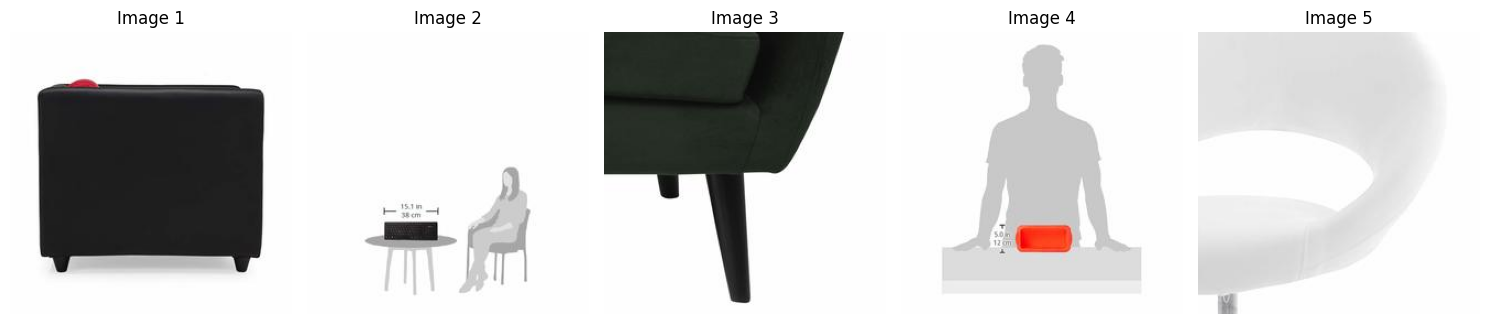

a wooden table


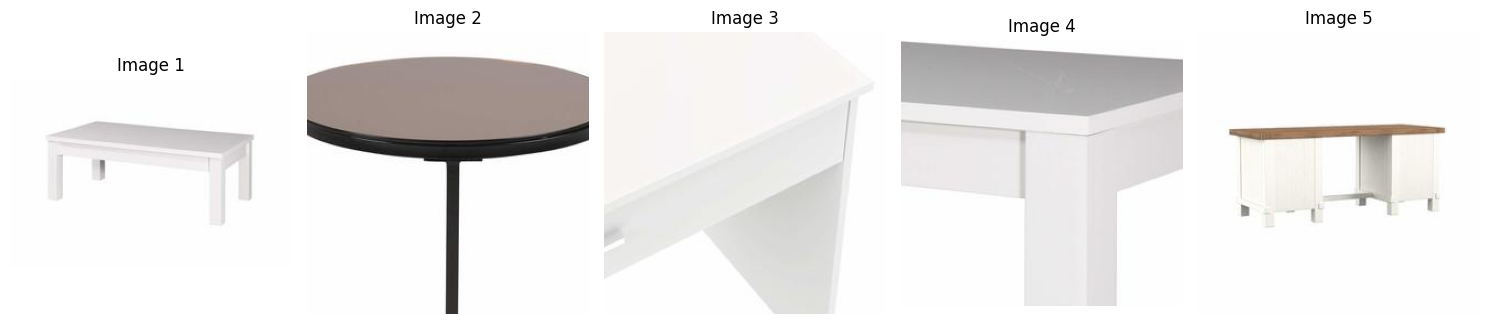

a blue backpack


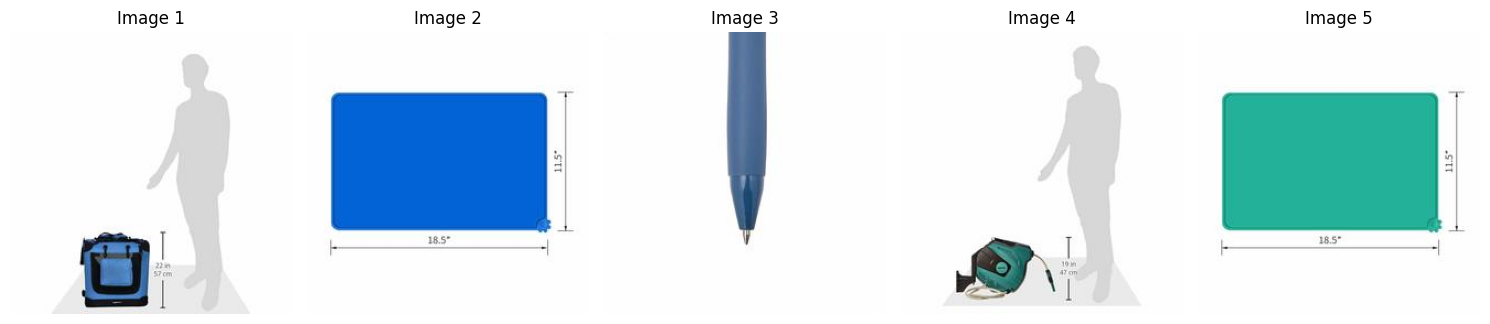

  0%|          | 0/1000 [00:00<?, ?it/s]

Liczba obrazów: 1000
a red chair


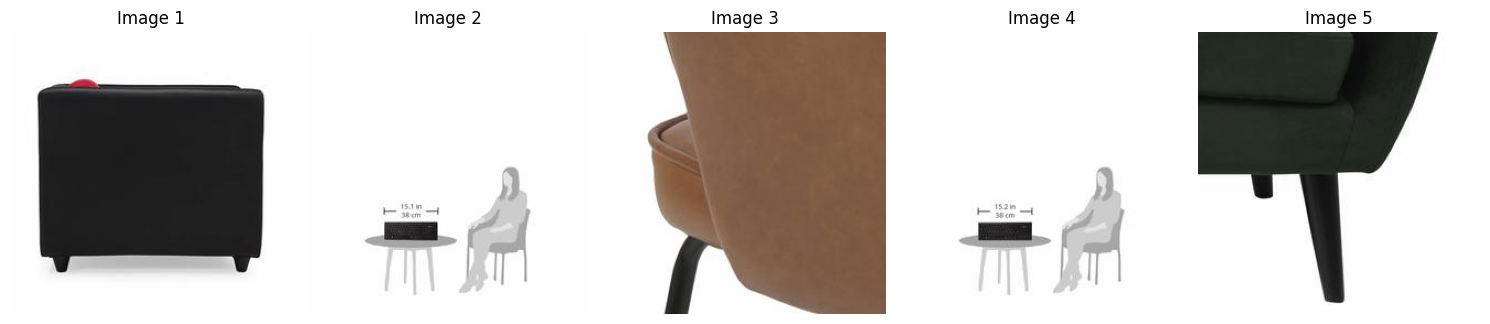

a wooden table


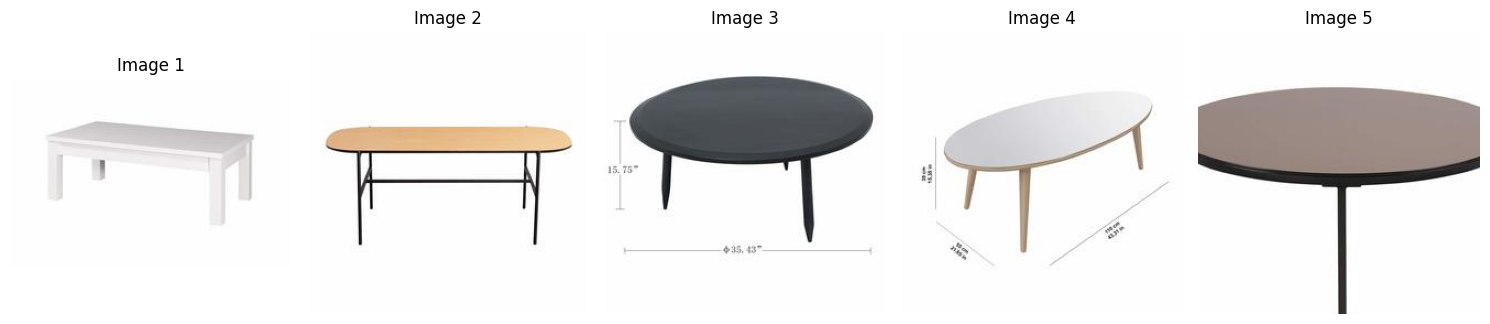

a blue backpack


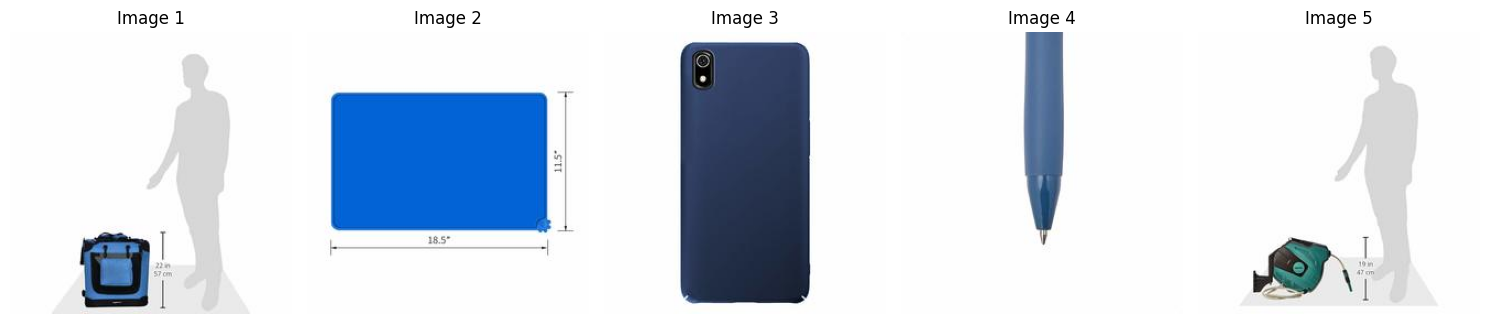

In [6]:
search = ImageSearch(engine, model)
queries = ["a red chair", "a wooden table", "a blue backpack"]

for MAX_IMAGES in (100, 500, 1000):
    with Session(engine) as session:
        session.execute(delete(Img))
        session.commit()
    vectorize_images(engine, model, image_paths)
    print("Liczba obrazów:", min(MAX_IMAGES, len(image_paths)))
    for query in queries:
        print(query)
        search(query, k=5)

## 7. Wnioski

1. Check a few different queries. Are results relevant?
* wyniki są umiarkowanie zgodne z zapytaniem. Dosyć często zdarzają się wyniki niezgodne z treścią zapytania

2. Check 3 different MAX_IMAGES sizes. Do you see more accurate results for larger datasets?
* tak, dla datasetu zawierającego 1000 rekordów wyniki, zwłaszcza dla zapytania `a wooden table` są dużo lepsze niż dla 100 rekordów
* pozostałe dwa przykładowe zapytania są na tyle specyficzne, że w wynikach dalej widzimy coś innego niż to, o co pytaliśmy
* jednakże nawet dla `a red chair` i `a blue backpack` wyniki dla największego datasetu są bardziej zgodne co do koloru lub przedmiotu zapytania względem mniejszych, mimo wciąż widocznych niezgodności z treścią zapytania dla każdego rozmiaru